## 统计目录下所有wav音频文件的长度

Processed 272 audio files


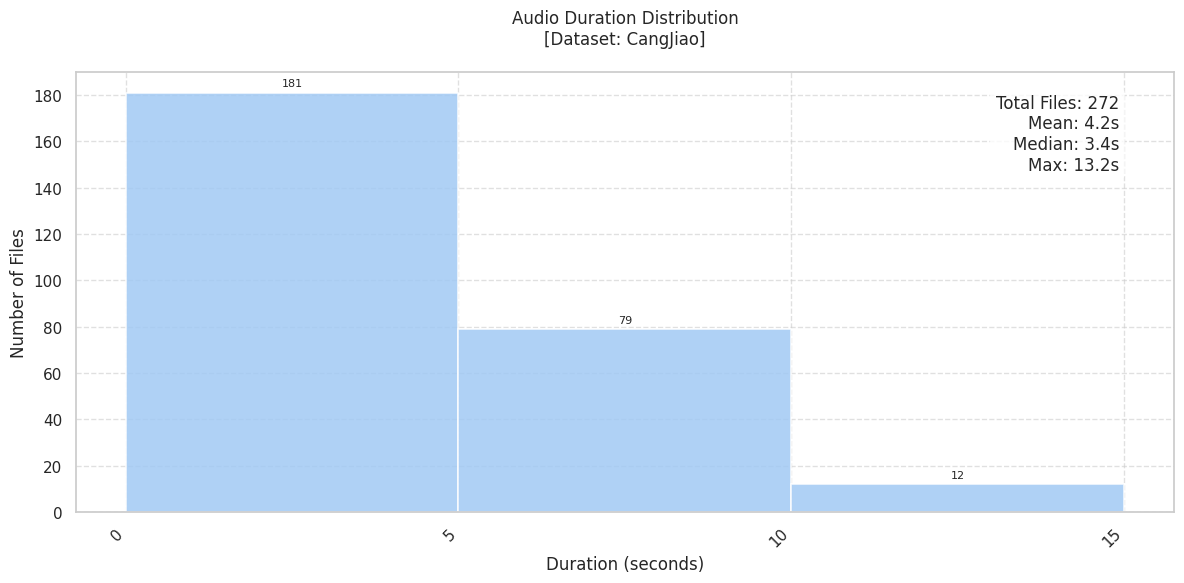

In [5]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from matplotlib.ticker import MaxNLocator

def get_audio_duration(file_path):
    try:
        y, sr = librosa.load(file_path, sr=None)
        duration = librosa.get_duration(y=y, sr=sr)
        return duration
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def process_directory(directory):
    durations = []
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.endswith('.wav'):
                file_path = os.path.join(root, file)
                duration = get_audio_duration(file_path)
                if duration is not None:
                    durations.append(duration)
    return durations

def plot_durations(durations):
    # 设置美观的样式
    sns.set(style="whitegrid", palette="pastel")
    plt.figure(figsize=(12, 6), dpi=100)

    # 自动计算分箱策略
    max_duration = np.max(durations)
    min_duration = np.min(durations)
    
    # 根据数据范围动态调整分箱
    if max_duration <= 60:  # 1分钟内的数据
        bin_step = 1 if max_duration < 10 else 5
        bins = np.arange(0, max_duration + bin_step, bin_step)
    else:  # 更长的数据使用对数分箱
        bins = np.logspace(np.log10(1), np.log10(max_duration), 15)
        bins = np.insert(bins, 0, 0)  # 确保包含0

    # 绘制直方图
    counts, bins, patches = plt.hist(
        durations, 
        bins=bins, 
        edgecolor='white', 
        linewidth=1.2,
        alpha=0.85
    )

    # 自动调整x轴刻度
    if max_duration > 60:
        plt.xscale('log')
        plt.xlabel('Duration (seconds, log scale)')
    else:
        plt.xticks(bins.round(1), rotation=45, ha='right')
        plt.xlabel('Duration (seconds)')

    # 添加统计信息
    mean_dur = np.mean(durations)
    median_dur = np.median(durations)
    stats_text = f"""Total Files: {len(durations)}
Mean: {mean_dur:.1f}s
Median: {median_dur:.1f}s
Max: {max_duration:.1f}s"""
    plt.gca().text(
        0.95, 0.95, stats_text,
        transform=plt.gca().transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )

    # 美化图表
    plt.title(f'Audio Duration Distribution\n[Dataset: {os.path.basename(directory)}]', pad=20)
    plt.ylabel('Number of Files')
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))  # Y轴只显示整数值
    plt.grid(True, which='both', linestyle='--', alpha=0.6)
    plt.tight_layout()

    # 添加数据标签
    for count, rect in zip(counts, patches):
        if count > 0:
            height = rect.get_height()
            plt.annotate(
                f'{int(count)}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=8
            )

    plt.show()

if __name__ == "__main__":
    directory = "/root/LLMs/data/VC/CangJiao"
    durations = process_directory(directory)
    
    if not durations:
        print("No valid audio files found!")
    else:
        print(f"Processed {len(durations)} audio files")
        plot_durations(durations)

## 如果音频是双声道需要转成单声道

In [6]:
import librosa

def check_audio_channels(wav_path):
    """检查音频文件的通道数"""
    y, sr = librosa.load(wav_path, sr=None, mono=False)  # mono=False 保留原始通道数
    if len(y.shape) == 1:
        print(f"音频 '{wav_path}' 是单声道 (Mono)")
    else:
        print(f"音频 '{wav_path}' 是双声道 (Stereo), 通道数: {y.shape[0]}")

# 示例：检查音频文件
wav_path = "/root/LLMs/data/VC/CangJiao/0a6b8a7bc7b34205.wav"  # 替换为你的音频文件路径
check_audio_channels(wav_path)

音频 '/root/LLMs/data/VC/CangJiao/0a6b8a7bc7b34205.wav' 是单声道 (Mono)


In [ ]:
# 双声道需要转成单声道，如果已经单声道，则无需运行

import os
from pydub import AudioSegment

def convert_to_mono(input_folder, output_folder):
    # 确保输出文件夹存在
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    # 遍历输入文件夹中的所有文件
    for filename in os.listdir(input_folder):
        if filename.endswith(".wav"):
            # 构建输入和输出文件的完整路径
            input_path = os.path.join(input_folder, filename)
            output_path = os.path.join(output_folder, filename)

            # 加载音频文件
            audio = AudioSegment.from_wav(input_path)

            # 将双声道转换为单声道
            mono_audio = audio.set_channels(1)

            # 导出单声道音频文件
            mono_audio.export(output_path, format="wav")

            print(f"Converted {filename} to mono and saved to {output_path}")

if __name__ == "__main__":
    input_folder = "/root/LLMs/data/music/clip_0"  # 替换为你的输入文件夹路径
    output_folder = "/root/LLMs/data/music/clip_0/mono"  # 替换为你的输出文件夹路径

    convert_to_mono(input_folder, output_folder)

## 将音频和list处理成数据集最终格式

In [7]:
import os

def process_slicer_list():
    # 定义路径常量
    audio_dir = "/root/LLMs/data/VC/CangJiao"
    list_path = "/root/LLMs/data/VC/CangJiao/0_CangJiao.list"
    
    try:
        with open(list_path, 'r', encoding='utf-8') as f:
            for line_number, line in enumerate(f, 1):
                try:
                    cleaned_line = line.strip()
                    if not cleaned_line:
                        continue

                    parts = cleaned_line.split('|', 3)
                    if len(parts) < 4:
                        raise ValueError(f"第{line_number}行字段不完整")

                    # 关键修复：去除文件名扩展名
                    raw_name = parts[0]
                    base_name = os.path.splitext(raw_name)[0]  # 去除扩展名
                    
                    output_path = os.path.join(audio_dir, f"{base_name}.normalized.txt")
                    asr_content = parts[3].strip()

                    with open(output_path, 'w', encoding='utf-8') as out_file:
                        out_file.write(asr_content)
                    
                    print(f"成功生成：{output_path}")

                except ValueError as ve:
                    print(f"格式错误：{str(ve)}")
                except Exception as e:
                    print(f"处理第{line_number}行时出错：{str(e)}")

    except FileNotFoundError:
        print(f"错误：列表文件 {list_path} 不存在")
    except Exception as e:
        print(f"系统错误：{str(e)}")

if __name__ == "__main__":
    process_slicer_list()

成功生成：/root/LLMs/data/VC/CangJiao/0037df4b80570969.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/009845cf5635011b.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/01c231e100b6ff35.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/028ebd5b23b562c9.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0343f3c0fd1d8e62.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/049eda2e50f85eba.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/05db0455eedddcb8.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/07430c89a85e03f2.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/08b7ea54516b8d3d.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/096ab6886cb3e906.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0a6b8a7bc7b34205.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0aa110679c70c9ea.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0ae9245c8fa35455.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0b5e5e8d7205d57f.normalized.txt
成功生成：/root/LLMs/data/VC/CangJiao/0ba6542ee17c5a12.normalized.txt
成功生成：/root/LLMs/data/VC/C